In [1]:
import pandas as pd, numpy as np, glob, joblib, time, os
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import classification_report, confusion_matrix, f1_score

try:
    from xgboost import XGBClassifier
    HAVE_XGB = True
except Exception as e:
    HAVE_XGB = False
print("All imports OK | XGBoost available:", HAVE_XGB)

Matplotlib is building the font cache; this may take a moment.


All imports OK | XGBoost available: False


In [2]:
LABEL_MAP = {
    "BENIGN": "Benign",
    "FTP-Patator": "BruteForce", "SSH-Patator": "BruteForce",
    "DoS Hulk": "DoS", "DoS GoldenEye": "DoS",
    "DoS slowloris": "DoS", "DoS Slowhttptest": "DoS",
    "PortScan": "PortScan",
}

def load_day(path, benign_cap=75_000):
    df = pd.read_csv(path, encoding="latin1")
    df.columns = df.columns.str.strip()            # column names have leading spaces
    df["Label"] = df["Label"].str.strip().map(LABEL_MAP)
    df = df.dropna(subset=["Label"])               # drop labels outside our 4 classes
    feats = df.columns.drop("Label")
    df[feats] = df[feats].replace([np.inf, -np.inf], np.nan).astype("float32")
    df = df.dropna()                               # remove rows with NaN/Inf
    benign = df[df.Label == "Benign"]
    if len(benign) > benign_cap:                   # sample benign down to save RAM
        benign = benign.sample(benign_cap, random_state=42)
    return pd.concat([benign, df[df.Label != "Benign"]])

In [3]:
frames = []
for f in sorted(glob.glob("data/*.csv")):
    t0 = time.time()
    d = load_day(f)
    print(f"{os.path.basename(f):55s} -> {d.shape}  ({time.time()-t0:.0f}s)")
    frames.append(d)

df = pd.concat(frames, ignore_index=True)
before = len(df)
df = df.drop_duplicates()                           # BEFORE splitting, to avoid leakage
print(f"\nDropped {before - len(df):,} duplicate rows")
print(f"Final shape: {df.shape}")
print(df.Label.value_counts())

Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv    -> (233804, 79)  (4s)
Monday-WorkingHours.pcap_ISCX.csv                       -> (75000, 79)  (8s)
Tuesday-WorkingHours.pcap_ISCX.csv                      -> (88832, 79)  (7s)
Wednesday-workingHours.pcap_ISCX.csv                    -> (326712, 79)  (11s)

Dropped 141,926 duplicate rows
Final shape: (582422, 79)
Label
Benign        288848
DoS           193730
PortScan       90694
BruteForce      9150
Name: count, dtype: int64


In [4]:
print("Classes:", sorted(df.Label.unique()))
print("Any NaN left:", df.drop(columns="Label").isna().any().any())
print("Number of features:", df.shape[1] - 1)
print("Memory (MB):", round(df.memory_usage(deep=True).sum() / 1e6))

df.to_pickle("data/clean_2017.pkl")                 # fast reload if the kernel restarts

Classes: ['Benign', 'BruteForce', 'DoS', 'PortScan']
Any NaN left: False
Number of features: 78
Memory (MB): 223


In [5]:
X = df.drop(columns="Label")
y = df["Label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("\nTrain class counts:\n", y_train.value_counts())
print("\nTest class counts:\n", y_test.value_counts())

Train: (465937, 78) | Test: (116485, 78)

Train class counts:
 Label
Benign        231078
DoS           154984
PortScan       72555
BruteForce      7320
Name: count, dtype: int64

Test class counts:
 Label
Benign        57770
DoS           38746
PortScan      18139
BruteForce     1830
Name: count, dtype: int64


In [6]:
t0 = time.time()
rf0 = RandomForestClassifier(n_estimators=50, n_jobs=-1, random_state=42)
rf0.fit(X_train, y_train)
print(f"Ranking forest trained in {time.time()-t0:.0f}s")

Ranking forest trained in 48s


Max Packet Length              0.0893
Packet Length Std              0.0825
Packet Length Variance         0.0714
Bwd Packet Length Max          0.0692
Avg Bwd Segment Size           0.0568
Packet Length Mean             0.0484
Average Packet Size            0.0462
Total Length of Bwd Packets    0.0418
Destination Port               0.0281
Fwd Packet Length Mean         0.0263
Bwd Packet Length Std          0.0239
Fwd Packet Length Max          0.0225
Flow IAT Max                   0.0225
Subflow Fwd Bytes              0.0224
Bwd Packet Length Mean         0.0214
Subflow Bwd Bytes              0.0199
Fwd IAT Mean                   0.0188
Avg Fwd Segment Size           0.0169
Bwd Packets/s                  0.0154
Flow Bytes/s                   0.0146
Init_Win_bytes_forward         0.0145
Flow IAT Std                   0.0139
Fwd IAT Total                  0.0135
ACK Flag Count                 0.0134
PSH Flag Count                 0.0120
dtype: float64

Destination Port in top 25: True


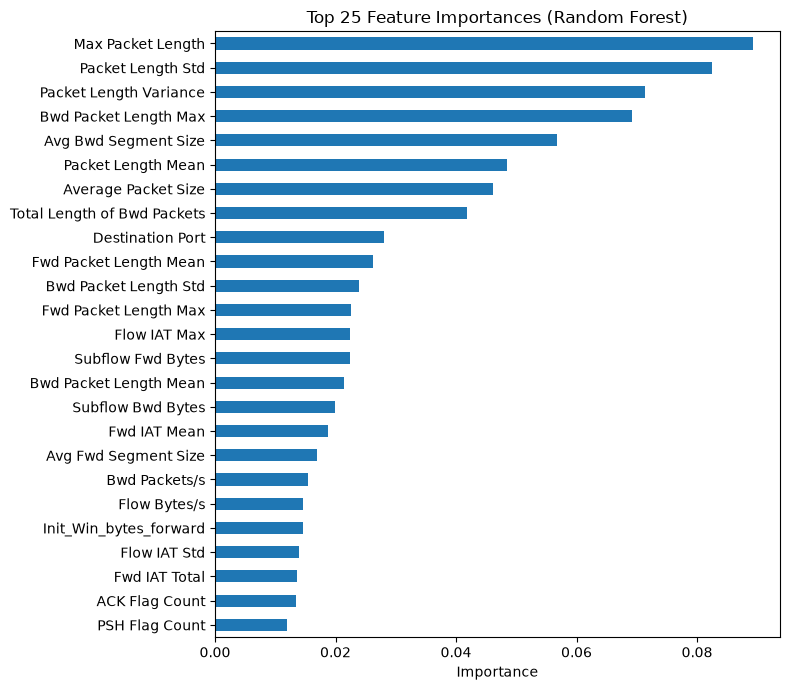

In [7]:
imp = pd.Series(rf0.feature_importances_, index=X.columns).sort_values(ascending=False)
top25 = imp.head(25).index.tolist()

print(imp.head(25).round(4))
print("\nDestination Port in top 25:", "Destination Port" in top25)

plt.figure(figsize=(8, 7))
imp.head(25)[::-1].plot(kind="barh")
plt.title("Top 25 Feature Importances (Random Forest)")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("figures/feature_importance.png", dpi=200)
plt.show()

imp.head(25).rename("importance").to_csv("figures/top25_features.csv")

In [8]:
X_train = X_train[top25]
X_test = X_test[top25]
print("Train:", X_train.shape, "| Test:", X_test.shape)

joblib.dump((X_train, X_test, y_train, y_test, top25), "data/split_2017.pkl")

Train: (465937, 25) | Test: (116485, 25)


['data/split_2017.pkl']

In [9]:
t0 = time.time()
rf = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced_subsample",   # gives the rare BruteForce class more weight
    n_jobs=-1,
    random_state=42,
)
rf.fit(X_train, y_train)
rf_time = time.time() - t0
print(f"Random Forest trained in {rf_time:.0f}s")

Random Forest trained in 82s


In [10]:
t0 = time.time()
if HAVE_XGB:
    gb_name = "XGBoost"
    le = LabelEncoder().fit(y_train)
    gb = XGBClassifier(n_estimators=200, max_depth=8, learning_rate=0.1,
                       n_jobs=-1, random_state=42, eval_metric="mlogloss",
                       tree_method="hist")
    gb.fit(X_train, le.transform(y_train),
           sample_weight=compute_sample_weight("balanced", y_train))
    gb_predict = lambda X: le.inverse_transform(gb.predict(X))
else:
    gb_name = "HistGradientBoosting"
    le = None
    gb = HistGradientBoostingClassifier(
        max_iter=200, max_depth=8, learning_rate=0.1,
        class_weight="balanced", random_state=42,
    ).fit(X_train, y_train)
    gb_predict = gb.predict
gb_time = time.time() - t0
print(f"{gb_name} trained in {gb_time:.0f}s")

HistGradientBoosting trained in 20s


In [11]:
rf_pred = rf.predict(X_test)
gb_pred = gb_predict(X_test)
print("RF macro F1 :", round(f1_score(y_test, rf_pred, average="macro"), 4))
print(f"{gb_name} macro F1:", round(f1_score(y_test, gb_pred, average="macro"), 4))

RF macro F1 : 0.9994
HistGradientBoosting macro F1: 0.9993


In [12]:
joblib.dump({"model": rf, "features": top25}, "models/rf_detector.joblib", compress=3)
joblib.dump({"model": gb, "features": top25, "encoder": le, "name": gb_name},
            "models/gb_detector.joblib", compress=3)

for f in ["rf_detector", "gb_detector"]:
    print(f, round(os.path.getsize(f"models/{f}.joblib") / 1e6, 1), "MB")

# Save timings and settings for your report
pd.DataFrame([
    {"model": "Random Forest", "train_seconds": round(rf_time), "settings": "100 trees, balanced_subsample"},
    {"model": gb_name, "train_seconds": round(gb_time), "settings": "200 iterations, depth 8, lr 0.1, balanced"},
]).to_csv("figures/training_times.csv", index=False)

rf_detector 3.6 MB
gb_detector 0.3 MB


In [13]:
from sklearn.metrics import accuracy_score

labels = sorted(y_test.unique())
rf_pred = rf.predict(X_test)
gb_pred = gb_predict(X_test)

print("=== Random Forest ===")
print(classification_report(y_test, rf_pred, labels=labels, digits=4))
print(f"=== {gb_name} ===")
print(classification_report(y_test, gb_pred, labels=labels, digits=4))

pd.DataFrame(classification_report(y_test, rf_pred, labels=labels, output_dict=True)).T.round(4).to_csv("figures/report_rf.csv")
pd.DataFrame(classification_report(y_test, gb_pred, labels=labels, output_dict=True)).T.round(4).to_csv("figures/report_gb.csv")

=== Random Forest ===
              precision    recall  f1-score   support

      Benign     0.9994    0.9996    0.9995     57770
  BruteForce     1.0000    0.9989    0.9995      1830
         DoS     0.9993    0.9991    0.9992     38746
    PortScan     0.9997    0.9993    0.9995     18139

    accuracy                         0.9994    116485
   macro avg     0.9996    0.9992    0.9994    116485
weighted avg     0.9994    0.9994    0.9994    116485

=== HistGradientBoosting ===
              precision    recall  f1-score   support

      Benign     0.9997    0.9993    0.9995     57770
  BruteForce     0.9989    0.9995    0.9992      1830
         DoS     0.9988    0.9996    0.9992     38746
    PortScan     0.9996    0.9993    0.9994     18139

    accuracy                         0.9994    116485
   macro avg     0.9993    0.9994    0.9993    116485
weighted avg     0.9994    0.9994    0.9994    116485



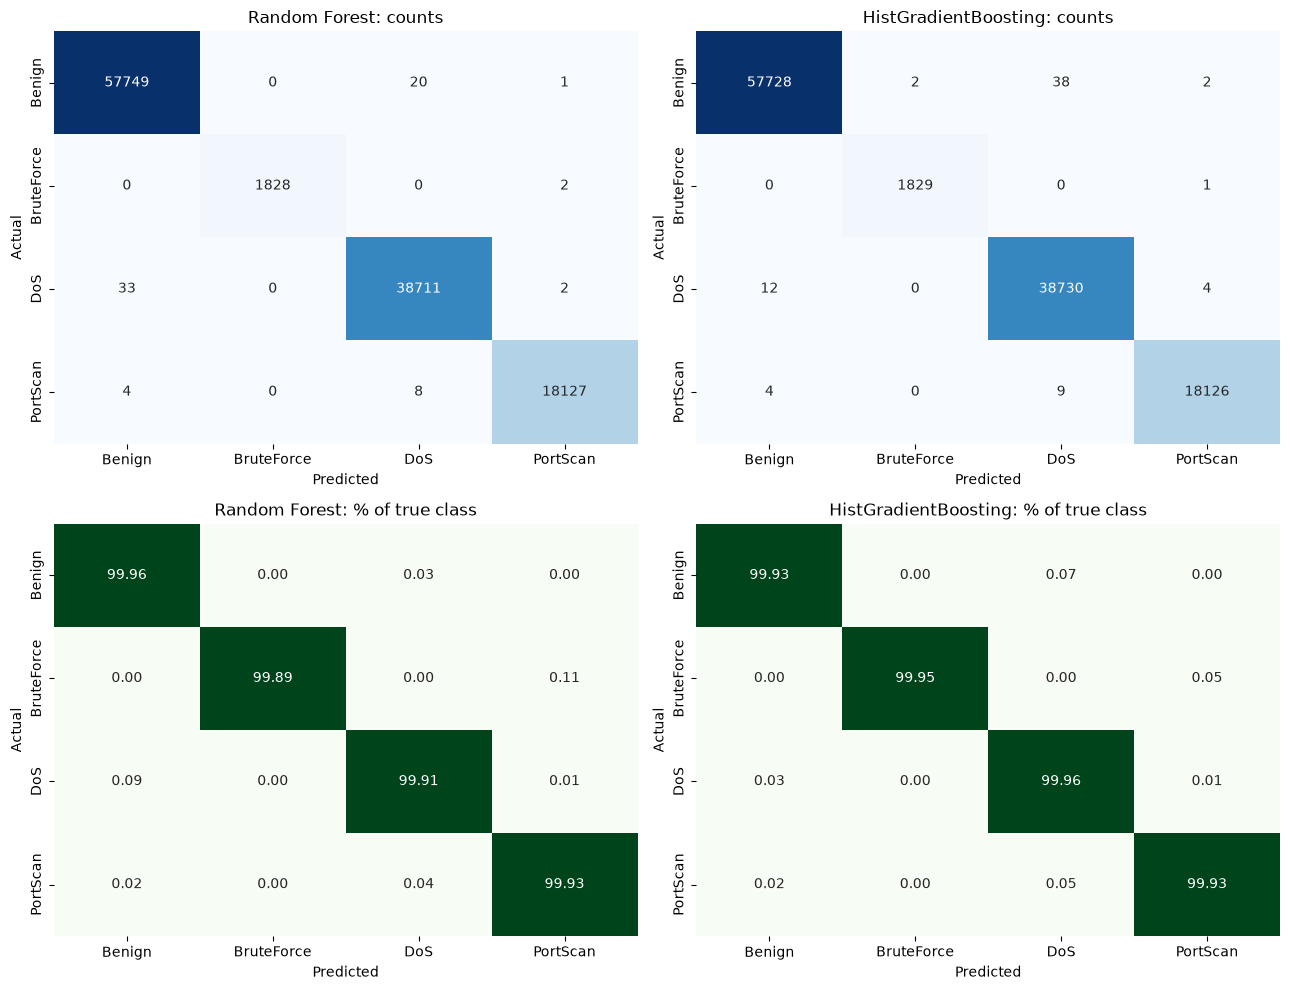

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for col, (pred, name) in enumerate([(rf_pred, "Random Forest"), (gb_pred, gb_name)]):
    cm = confusion_matrix(y_test, pred, labels=labels)
    cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=labels, yticklabels=labels, ax=axes[0, col])
    axes[0, col].set_title(f"{name}: counts")
    sns.heatmap(cm_pct, annot=True, fmt=".2f", cmap="Greens", cbar=False,
                xticklabels=labels, yticklabels=labels, ax=axes[1, col])
    axes[1, col].set_title(f"{name}: % of true class")
    for r in (0, 1):
        axes[r, col].set_xlabel("Predicted"); axes[r, col].set_ylabel("Actual")
plt.tight_layout()
plt.savefig("figures/confusion_matrices.png", dpi=200)
plt.show()

In [15]:
rows = []
for name, model_predict, tt in [("Random Forest", rf.predict, rf_time), (gb_name, gb_predict, gb_time)]:
    t0 = time.time()
    pred = model_predict(X_test)
    pred_time = time.time() - t0
    row = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Macro F1": f1_score(y_test, pred, average="macro"),
        "Weighted F1": f1_score(y_test, pred, average="weighted"),
        "Train time (s)": round(tt),
        "Predict time, all test flows (s)": round(pred_time, 2),
    }
    f1s = f1_score(y_test, pred, average=None, labels=labels)
    row.update({f"F1 {l}": v for l, v in zip(labels, f1s)})
    rows.append(row)

results = pd.DataFrame(rows).round(4)
print(results.T.to_string(header=False))
results.to_csv("figures/model_comparison.csv", index=False)

Model                             Random Forest  HistGradientBoosting
Accuracy                                 0.9994                0.9994
Macro F1                                 0.9994                0.9993
Weighted F1                              0.9994                0.9994
Train time (s)                               82                    20
Predict time, all test flows (s)           0.64                  1.04
F1 Benign                                0.9995                0.9995
F1 BruteForce                            0.9995                0.9992
F1 DoS                                   0.9992                0.9992
F1 PortScan                              0.9995                0.9994


In [16]:
if "Destination Port" in top25:
    no_port = [f for f in top25 if f != "Destination Port"]
    rf_np = RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample",
                                   n_jobs=-1, random_state=42).fit(X_train[no_port], y_train)
    pred_np = rf_np.predict(X_test[no_port])

    print("Macro F1 with Destination Port   :", round(f1_score(y_test, rf_pred, average="macro"), 4))
    print("Macro F1 without Destination Port:", round(f1_score(y_test, pred_np, average="macro"), 4))
    comp = pd.DataFrame({
        "F1 with port": f1_score(y_test, rf_pred, average=None, labels=labels),
        "F1 without port": f1_score(y_test, pred_np, average=None, labels=labels),
    }, index=labels).round(4)
    print(comp)
    comp.to_csv("figures/ablation_destination_port.csv")
    print(classification_report(y_test, pred_np, labels=labels, digits=4))
else:
    print("Destination Port is not in your top 25, so there is nothing to ablate. Mention that in the report.")

Macro F1 with Destination Port   : 0.9994
Macro F1 without Destination Port: 0.9985
            F1 with port  F1 without port
Benign            0.9995           0.9990
BruteForce        0.9995           0.9970
DoS               0.9992           0.9985
PortScan          0.9995           0.9995
              precision    recall  f1-score   support

      Benign     0.9989    0.9990    0.9990     57770
  BruteForce     0.9962    0.9978    0.9970      1830
         DoS     0.9985    0.9985    0.9985     38746
    PortScan     0.9997    0.9994    0.9995     18139

    accuracy                         0.9989    116485
   macro avg     0.9983    0.9987    0.9985    116485
weighted avg     0.9989    0.9989    0.9989    116485



In [17]:
MAP_2017_TO_2018 = {
    "Destination Port": "Dst Port",
    "Total Fwd Packets": "Tot Fwd Pkts", "Total Backward Packets": "Tot Bwd Pkts",
    "Total Length of Fwd Packets": "TotLen Fwd Pkts", "Total Length of Bwd Packets": "TotLen Bwd Pkts",
    "Fwd Packet Length Max": "Fwd Pkt Len Max", "Fwd Packet Length Min": "Fwd Pkt Len Min",
    "Fwd Packet Length Mean": "Fwd Pkt Len Mean", "Fwd Packet Length Std": "Fwd Pkt Len Std",
    "Bwd Packet Length Max": "Bwd Pkt Len Max", "Bwd Packet Length Min": "Bwd Pkt Len Min",
    "Bwd Packet Length Mean": "Bwd Pkt Len Mean", "Bwd Packet Length Std": "Bwd Pkt Len Std",
    "Flow Bytes/s": "Flow Byts/s", "Flow Packets/s": "Flow Pkts/s",
    "Fwd Header Length": "Fwd Header Len", "Bwd Header Length": "Bwd Header Len",
    "Fwd Packets/s": "Fwd Pkts/s", "Bwd Packets/s": "Bwd Pkts/s",
    "Min Packet Length": "Pkt Len Min", "Max Packet Length": "Pkt Len Max",
    "Packet Length Mean": "Pkt Len Mean", "Packet Length Std": "Pkt Len Std",
    "Packet Length Variance": "Pkt Len Var",
    "FIN Flag Count": "FIN Flag Cnt", "SYN Flag Count": "SYN Flag Cnt",
    "RST Flag Count": "RST Flag Cnt", "PSH Flag Count": "PSH Flag Cnt",
    "ACK Flag Count": "ACK Flag Cnt", "URG Flag Count": "URG Flag Cnt",
    "ECE Flag Count": "ECE Flag Cnt",
    "Average Packet Size": "Pkt Size Avg",
    "Avg Fwd Segment Size": "Fwd Seg Size Avg", "Avg Bwd Segment Size": "Bwd Seg Size Avg",
    "Fwd Avg Bytes/Bulk": "Fwd Byts/b Avg", "Fwd Avg Packets/Bulk": "Fwd Pkts/b Avg",
    "Fwd Avg Bulk Rate": "Fwd Blk Rate Avg", "Bwd Avg Bytes/Bulk": "Bwd Byts/b Avg",
    "Bwd Avg Packets/Bulk": "Bwd Pkts/b Avg", "Bwd Avg Bulk Rate": "Bwd Blk Rate Avg",
    "Subflow Fwd Packets": "Subflow Fwd Pkts", "Subflow Fwd Bytes": "Subflow Fwd Byts",
    "Subflow Bwd Packets": "Subflow Bwd Pkts", "Subflow Bwd Bytes": "Subflow Bwd Byts",
    "Init_Win_bytes_forward": "Init Fwd Win Byts", "Init_Win_bytes_backward": "Init Bwd Win Byts",
    "act_data_pkt_fwd": "Fwd Act Data Pkts", "min_seg_size_forward": "Fwd Seg Size Min",
}
need = {MAP_2017_TO_2018.get(f, f): f for f in top25}     # 2018 name -> 2017 name

def map_label_2018(s):
    s = str(s).lower()
    if "benign" in s: return "Benign"
    if "brute" in s or "patator" in s: return "BruteForce"
    if "dos" in s: return "DoS"
    return None

In [18]:
def load_2018(path, cap_per_class=50_000):
    cols = pd.read_csv(path, nrows=0).columns
    keep = [c for c in cols if c.strip() in need or c.strip() == "Label"]
    df = pd.read_csv(path, usecols=keep, low_memory=False)
    df.columns = df.columns.str.strip()
    df = df[df["Label"] != "Label"]                      # some files repeat the header row
    df["RawLabel"] = df["Label"]                         # keep the original attack name
    df["Label"] = df["Label"].map(map_label_2018)
    df = df.dropna(subset=["Label"]).rename(columns=need)

    missing = [f for f in top25 if f not in df.columns]
    print(os.path.basename(path), "| missing features:", missing)
    if missing:
        print("2018 columns available:", sorted(cols.str.strip()))
        raise ValueError("Some features are missing, see list above")

    for c in top25:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    df[top25] = df[top25].replace([np.inf, -np.inf], np.nan)
    df = df.dropna().drop_duplicates()
    parts = [g.sample(min(len(g), cap_per_class), random_state=42) for _, g in df.groupby("RawLabel")]
    return pd.concat(parts)

d18 = pd.concat([load_2018(f) for f in sorted(glob.glob("data2018/*.csv"))], ignore_index=True)
print(d18.groupby(["Label", "RawLabel"]).size())

Friday-16-02-2018_TrafficForML_CICFlowMeter.csv | missing features: ['Fwd IAT Total']
2018 columns available: ['ACK Flag Cnt', 'Active Max', 'Active Mean', 'Active Min', 'Active Std', 'Bwd Blk Rate Avg', 'Bwd Byts/b Avg', 'Bwd Header Len', 'Bwd IAT Max', 'Bwd IAT Mean', 'Bwd IAT Min', 'Bwd IAT Std', 'Bwd IAT Tot', 'Bwd PSH Flags', 'Bwd Pkt Len Max', 'Bwd Pkt Len Mean', 'Bwd Pkt Len Min', 'Bwd Pkt Len Std', 'Bwd Pkts/b Avg', 'Bwd Pkts/s', 'Bwd Seg Size Avg', 'Bwd URG Flags', 'CWE Flag Count', 'Down/Up Ratio', 'Dst Port', 'ECE Flag Cnt', 'FIN Flag Cnt', 'Flow Byts/s', 'Flow Duration', 'Flow IAT Max', 'Flow IAT Mean', 'Flow IAT Min', 'Flow IAT Std', 'Flow Pkts/s', 'Fwd Act Data Pkts', 'Fwd Blk Rate Avg', 'Fwd Byts/b Avg', 'Fwd Header Len', 'Fwd IAT Max', 'Fwd IAT Mean', 'Fwd IAT Min', 'Fwd IAT Std', 'Fwd IAT Tot', 'Fwd PSH Flags', 'Fwd Pkt Len Max', 'Fwd Pkt Len Mean', 'Fwd Pkt Len Min', 'Fwd Pkt Len Std', 'Fwd Pkts/b Avg', 'Fwd Pkts/s', 'Fwd Seg Size Avg', 'Fwd Seg Size Min', 'Fwd URG Fl

ValueError: Some features are missing, see list above

In [19]:
MAP_2017_TO_2018.update({
    "Fwd IAT Total": "Fwd IAT Tot",
    "Bwd IAT Total": "Bwd IAT Tot",
})
need = {MAP_2017_TO_2018.get(f, f): f for f in top25}
print("Mapped features:", len(need), "of", len(top25))

Mapped features: 25 of 25


In [20]:
def load_2018(path, cap_per_class=50_000):
    cols = pd.read_csv(path, nrows=0).columns
    keep = [c for c in cols if c.strip() in need or c.strip() == "Label"]
    df = pd.read_csv(path, usecols=keep, low_memory=False)
    df.columns = df.columns.str.strip()
    df = df[df["Label"] != "Label"]                      # some files repeat the header row
    df["RawLabel"] = df["Label"]                         # keep the original attack name
    df["Label"] = df["Label"].map(map_label_2018)
    df = df.dropna(subset=["Label"]).rename(columns=need)

    missing = [f for f in top25 if f not in df.columns]
    print(os.path.basename(path), "| missing features:", missing)
    if missing:
        print("2018 columns available:", sorted(cols.str.strip()))
        raise ValueError("Some features are missing, see list above")

    for c in top25:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    df[top25] = df[top25].replace([np.inf, -np.inf], np.nan)
    df = df.dropna().drop_duplicates()
    parts = [g.sample(min(len(g), cap_per_class), random_state=42) for _, g in df.groupby("RawLabel")]
    return pd.concat(parts)

d18 = pd.concat([load_2018(f) for f in sorted(glob.glob("data2018/*.csv"))], ignore_index=True)
print(d18.groupby(["Label", "RawLabel"]).size())

Friday-16-02-2018_TrafficForML_CICFlowMeter.csv | missing features: []
Wednesday-14-02-2018_TrafficForML_CICFlowMeter.csv | missing features: []
Label       RawLabel                
Benign      Benign                      100000
BruteForce  FTP-BruteForce                  53
            SSH-Bruteforce               50000
DoS         DoS attacks-Hulk             50000
            DoS attacks-SlowHTTPTest        55
dtype: int64


In [ ]:
X18 = d18[top25].astype("float32")
y18 = d18["Label"]
labels4 = sorted(y_train.unique())                        # includes PortScan so the matrix shows false PortScan alarms
present = sorted(y18.unique())

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
all_rows = []
for ax, (name, predict) in zip(axes, [("Random Forest", rf.predict), (gb_name, gb_predict)]):
    pred = pd.Series(predict(X18), index=d18.index)
    print(f"\n===== {name} on CSE-CIC-IDS2018 =====")
    print(classification_report(y18, pred, labels=present, digits=4, zero_division=0))

    rows = []
    for raw, grp in d18.groupby("RawLabel"):
        p = pred[grp.index]
        rows.append({"Model": name, "2018 class": raw, "n": len(grp),
                     "Correct class %": round((p == grp.Label).mean() * 100, 2),
                     "Flagged as any attack %": round((p != "Benign").mean() * 100, 2)})
    tbl = pd.DataFrame(rows)
    print(tbl.drop(columns="Model").to_string(index=False))
    all_rows.append(tbl)

    cm = confusion_matrix(y18, pred, labels=labels4)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Oranges", cbar=False,
                xticklabels=labels4, yticklabels=labels4, ax=ax)
    ax.set_title(f"{name}: trained on 2017, tested on 2018")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")

plt.tight_layout()
plt.savefig("figures/cross_dataset_cm.png", dpi=200)
plt.show()
pd.concat(all_rows).to_csv("figures/cross_dataset_results.csv", index=False)